# Shear Buckling of a Hat-Stiffened Panel

__William L. Ko__, NASA Dryden Flight Research Center, Edwards, California

__Raymond H. Jackson__, NASA Dryden Flight Research Center, Edwards, California

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The model is the local shear buckling load of a hat-stiffened panel from Ko and Jackson, NASA Technical Memorandum 4644 (1994) [[1]][R1]. **The formula and the input distributions were taken from the OpenTURNS "stiffened panel" use case [[2]][R2]** (documentation and the use-case code, version 1.25.1), which cites the memorandum, **with one change: the thickness range is ten times the one coded in OpenTURNS.** The OpenTURNS range, about 0.0032 in, gives a buckling load about 800 times below the memorandum's 900 lb/in and appears to be a factor-10 slip; the data here follow the memorandum's panel (a sheet about 0.032 in thick), and the OpenTURNS-as-coded thickness is kept as a variant computed in this notebook. The memorandum is on the NASA Technical Reports Server (19950011075), but the only text of it we could read was a machine extraction of the scan, with garbled equations and no legible dimensions, so we could not check the formula or the thickness against it directly. No OpenTURNS code (LGPL) was copied: `panel_model.py` is written from the equations. The notebook runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes a few seconds.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import panel_model as pm

SEED = 1994                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
names = list(pm.NAMES)
labels = [r'$E$', r'$\nu$', r'$h_c$', r'$\ell$', r'$f_1$', r'$f_2$', r'$t$', r'$a$', r'$b_0$', r'$p$']

### Summary

The critical shear load of the face-sheet strip between two hat stiffeners, a closed-form flat-plate buckling formula with a correction for the shear carried by the hat, depends on ten geometric and material inputs with narrow uniform and truncated-normal distributions (OpenTURNS's, with the thickness ten times the OpenTURNS range to match the memorandum's panel), two of which, the widths of the stiffener foot and hat, are dependent through a normal copula with Spearman correlation $-0.8$. With exact gradients at 5000 points, every input centred and scaled by its standard deviation and the dependent pair decorrelated, we find a one-dimensional active subspace with $\lambda_1/\lambda_2 = 1188$ (99.895 % of the trace), led by the Young modulus ($+0.885$), then the stiffener flank length, the thickness and the stiffener spacing, on which a line in the active variable has leave-one-out $R^2 = 0.999013$; Nataf-transformed variables give the same direction ($|\mathbf w_1\cdot\mathbf w_1'| = 0.9992$) with $\lambda_1/\lambda_2 = 34.8$. At the midpoint the load is 1107 lb/in, 1.23 times the memorandum's 900 lb/in finite-element value, which the memorandum says its closed-form prediction slightly exceeds, whereas the OpenTURNS-as-coded thickness gives 1.13 lb/in, 797 times too low, with the same active subspace ($|\mathbf w_1\cdot\mathbf w_1| = 0.999904$).

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. When inputs are dependent, $\mathbf C$ is still the average over their joint density, but the normalized inputs should be uncorrelated so that a unit step means the same in every direction; here the normalization includes a Cholesky decorrelation. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015 [[4]][R4].

### The model

A hat-stiffened panel is a flat face sheet with hat-shaped stiffeners bonded to it. Under in-plane shear, the face-sheet strip between two consecutive stiffener feet, of width $b_0$, buckles first (local buckling). Ko and Jackson [[1]][R1] model the strip as a long, simply supported flat plate, with the shear buckling coefficient $k_{xy} = 5.35 + 4(b/a)^2$ (5.35 for an infinitely long strip, 9.34 for a square plate), and account for the part of the panel's shear flow carried by the hat. As given by OpenTURNS [[2]][R2] for a face sheet and a hat of the same thickness $t$ and material ($E$, $\nu$), the critical shear load (a force per unit length) is

$$
(N_{xy})_{cr} = \left(5.35 + 4\left(\frac{b_0}{a}\right)^2\right)\frac{\pi^2}{b_0^2}\,\frac{E\,t^3}{12(1-\nu^2)}\;Q,\qquad
Q = 1 + \frac14\,\frac{2p\,(h - 2h_0) - h_c\,(f_1 - f_2)}{h_0\,\ell},
$$

with $A = \ell t$, $\bar A = A + t\,(p + (f_1 - f_2)/2)$, $h_0 = \dfrac{A\,(h_c + 2t) + t^2(f_1 - f_2)}{2\bar A}$ and $h = h_c + t$. Here $h_c$ is the distance between the mean surfaces of the hat top and the stiffener foot, $\ell$ the length of the stiffener flank, $f_1$ and $f_2$ the widths of the stiffener foot and hat, $p$ the half-width of the stiffener, $a$ the panel width (its long side) and $b_0$ the distance between two stiffener feet. The first three factors are the flat-strip load; $Q$, the hat correction, is about 1.31.

**Quantity of interest.** $(N_{xy})_{cr}$ in N/m (OpenTURNS labels it a force in N; dimensionally it is a shear flow, N/m). It is smooth on the whole input domain, and its gradient is exact (`panel_model.grad_buckling_load`, checked below and against a complex step in `generate_data.py`). Two structural facts show up in the results: the load depends on $f_1$ and $f_2$ only through $f_1 - f_2$, so equal steps in both change nothing (an exactly zero eigenvalue), and, because $h_0$ and the numerator of $Q$ are both nearly proportional to $h_c$ when $t \ll h_c$, the load hardly depends on $h_c$.

**Inputs.** The ten inputs and their distributions are those of OpenTURNS [[2]][R2], except the thickness $t$: $E$ a normal law $\mathcal N(110\times10^9, 55\times10^9)$ Pa (mean, standard deviation) truncated to $[99, 121]\times10^9$ Pa, the other nine uniform. Because the parent standard deviation is five times the half-width of the truncation interval, the truncated $E$ is almost uniform (the next cell compares the two standard deviations). $f_1$ and $f_2$ are dependent through a normal copula with Spearman correlation $-0.8$: the OpenTURNS code (`stiffened_panel.py`, v1.25.1) puts $-0.8$ in a matrix that it passes through `NormalCopula.GetCorrelationFromSpearmanCorrelation`, so the copula parameter is $2\sin(-0.8\pi/6) = -0.8135$, and we do the same. **The thickness** is uniform on $[8.02, 8.181]\times10^{-4}$ m (0.0316–0.0322 in), ten times the OpenTURNS range $[8.02, 8.181]\times10^{-5}$ m; the reasons are in the comparison with the memorandum. The table is built from `panel_model.py`; the means and standard deviations are exact.

In [2]:
mean, cov = pm.mean_and_cov()
sd = np.sqrt(np.diag(cov))
print(f"{'input':5s} {'units':5s} {'distribution (OpenTURNS)':40s} {'mean':>11s} {'std':>10s} {'std/mean':>8s}  description")
for j, n in enumerate(names):
    print(f'{n:5s} {pm.UNITS[j]:5s} {pm.DISTRIBUTIONS[j]:40s} {mean[j]:11.5g} {sd[j]:10.4g} {sd[j] / mean[j]:8.4f}  '
          f'{pm.DESCRIPTIONS[j]}')
print(f'\nnormal copula between f_1 and f_2: Spearman correlation {pm.SPEARMAN_F1F2} (= Pearson for these uniform '
      f'marginals; check {pm.spearman_of_copula():.4f}), copula parameter r = 2 sin(pi (-0.8)/6) = {pm.R_COPULA:.4f}')
print(f'thickness t: U({pm.LOWER[6]:g}, {pm.UPPER[6]:g}) m, ten times the OpenTURNS range '
      f'U({pm.T_OPENTURNS[0]:g}, {pm.T_OPENTURNS[1]:g}) m; in inches {pm.LOWER[6] / 0.0254:.4f} to {pm.UPPER[6] / 0.0254:.4f} '
      f'(midpoint {pm.NOMINAL[6] / 0.0254:.4f} in; OpenTURNS {pm.NOMINAL_OPENTURNS[6] / 0.0254:.5f} in)')
print(f'E: sd of the truncated normal {sd[0]:.4e} Pa; a uniform law on [99e9, 121e9] would have {22e9 / np.sqrt(12):.4e} Pa')
LBF_PER_IN = 4.4482216152605 / 0.0254   # N/m in one lb/in
q = pm.intermediates(pm.NOMINAL)
print(f"at the midpoint of every range: k_xy = {q['kxy']:.4f}, hat correction Q = {q['Q']:.4f}, "
      f"(N_xy)_cr = {pm.buckling_load(pm.NOMINAL):.1f} N/m = {pm.buckling_load(pm.NOMINAL) / LBF_PER_IN:.1f} lb/in")

input units distribution (OpenTURNS)                        mean        std std/mean  description
E     Pa    TruncatedNormal(110e9, 55e9, [99e9, 121e9])     1.1e+11  6.334e+09   0.0576  Young modulus
nu    -     Uniform(0.3675, 0.3825)                        0.375    0.00433   0.0115  Poisson coefficient
h_c   m     Uniform(0.0285, 0.0315)                         0.03   0.000866   0.0289  distance between the mean surfaces of the hat and the foot of the stiffener
ell   m     Uniform(0.04655, 0.05145)                      0.049   0.001415   0.0289  length of the stiffener side (flank)
f_1   m     Uniform(0.0266, 0.0294)                        0.028  0.0008083   0.0289  width of the stiffener foot
f_2   m     Uniform(0.00627, 0.00693)                     0.0066  0.0001905   0.0289  width of the stiffener hat
t     m     Uniform(0.000802, 0.0008181)              0.00081005  4.648e-06   0.0057  thickness of the panel and the stiffener
a     m     Uniform(0.6039, 0.6161)                   

The relative spreads are narrow: 5.8 % (one standard deviation) for $E$, 2.9 % for $h_c$, $\ell$, $f_1$, $f_2$, and under 1.2 % for the others. At the midpoint of every range the load is 193859.1 N/m = 1107.0 lb/in, with $Q = 1.3060$.

### Load data

`generate_data.py` drew $M = 5000$ Monte Carlo samples of the inputs by the inverse CDF (seed 1994; for the copula, $f_1$ first, then $f_2$ given $f_1$) and wrote the physical inputs, $(N_{xy})_{cr}$, and its exact gradient with respect to the physical inputs (see `DATA.md`).

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')        # (M, 10) physical inputs
f = np.loadtxt('outputs.csv', delimiter=',')       # (M,) (N_xy)_cr in N/m
G = np.loadtxt('gradients.csv', delimiter=',')     # (M, 10) exact d(N_xy)_cr/dx, physical inputs
print(f'inputs {X.shape}, outputs {f.shape}, gradients {G.shape}')

inputs (5000, 10), outputs (5000,), gradients (5000, 10)


We check the files against the model and the exact gradients against central finite differences (step $10^{-6}$ standard deviations), compare the sample rank correlation of $f_1$ and $f_2$ with the copula's, and look at the spread of the load. All inputs are positive lengths or moduli in narrow ranges, so no sample lies outside physical meaning (`generate_data.py` counts 0 samples with a non-positive length, $\nu \ge 0.5$, $f_2 \ge f_1$, $2t \ge h_c$, $h_0 \le 0$ or $Q \le 0$).

In [4]:
h = 1e-6 * sd
G_fd = np.column_stack([(pm.buckling_load(X + h[j] * e) - pm.buckling_load(X - h[j] * e)) / (2 * h[j])
                        for j, e in enumerate(np.eye(10))])
print(f'max |model - outputs.csv| = {np.max(np.abs(pm.buckling_load(X) - f)):.1e} N/m; gradients vs central '
      f'differences: max relative error {np.max(np.linalg.norm(G_fd - G, axis=1) / np.linalg.norm(G, axis=1)):.1e}')
rank = lambda v: np.argsort(np.argsort(v))
print(f'sample Spearman(f_1, f_2) = {np.corrcoef(rank(X[:, 4]), rank(X[:, 5]))[0, 1]:.4f} '
      f'(exact {pm.SPEARMAN_F1F2}); f_1 - f_2 in [{(X[:, 4] - X[:, 5]).min():.5f}, '
      f'{(X[:, 4] - X[:, 5]).max():.5f}] m')
se = f.std(ddof=1) / np.sqrt(len(f))
print(f'(N_xy)_cr: sample mean {f.mean():.0f} N/m (95% interval {f.mean() - 1.96 * se:.0f} to {f.mean() + 1.96 * se:.0f}), '
      f'sd {f.std(ddof=1):.0f} N/m, coefficient of variation {f.std(ddof=1) / f.mean():.4f}; '
      f'range [{f.min():.0f}, {f.max():.0f}] N/m = [{f.min() / LBF_PER_IN:.0f}, {f.max() / LBF_PER_IN:.0f}] lb/in')
q = pm.intermediates(X)
print(f"hat correction Q in [{q['Q'].min():.4f}, {q['Q'].max():.4f}]; h0 in [{q['h0'].min():.5f}, {q['h0'].max():.5f}] m")

max |model - outputs.csv| = 0.0e+00 N/m; gradients vs central differences: max relative error 3.4e-08
sample Spearman(f_1, f_2) = -0.7971 (exact -0.8); f_1 - f_2 in [0.01967, 0.02313] m
(N_xy)_cr: sample mean 194195 N/m (95% interval 193840 to 194550), sd 12803 N/m, coefficient of variation 0.0659; range [160849, 230534] N/m = [918, 1316] lb/in
hat correction Q in [1.2368, 1.3841]; h0 in [0.00737, 0.00865] m


### Estimate the subspace

The model is closed-form, so we use exact gradients and the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates. The samples keep their true distributions; the input space only says how the inputs are normalized, and the library applies that map once to the physical inputs and gradients we pass:

- **Every input is centred at its exact mean and scaled by its exact standard deviation**, and the dependent pair $(f_1, f_2)$ is decorrelated: $\mathbf u = \mathbf L^{-1}(\mathbf x - \boldsymbol\mu)$ with $\mathbf L\mathbf L^T = \boldsymbol\Sigma$ the exact covariance (`panel_model.mean_and_cov`). One `ac.Gaussian(mean, cov)` block gives this map; it is used only for its affine map and does not make the samples Gaussian. Since $\boldsymbol\Sigma$ is diagonal except for the $(f_1, f_2)$ entry, $u_j = (x_j - \mu_j)/\sigma_j$ for eight inputs, $u_{f_1}$ is the scaled $f_1$, and $u_{f_2}$ is the part of the scaled $f_2$ uncorrelated with $f_1$ (Cholesky order $f_1$, then $f_2$).
- No input gets a half-range scale: the uniforms and the truncated normal are all scaled by their standard deviations.

The normalized gradient is $\mathbf L^T\nabla_{\mathbf x} f$. We use 500 bootstrap replicates and the library's eigenvalue-gap rule. Two other normalizations follow the results: a Nataf transform of every input to a standard normal, and a scaling that ignores the correlation.

In [5]:
space = ac.Gaussian(mean, cov, names=names)    # affine map L^{-1}(x - mean), cov = L L^T (exact moments)
sub = ac.active_subspace(space=space, X=X, f=f, grads=G, estimator='as', nboot=500, rng=SEED)
sub = ac.orient(sub, by='mean_gradient', grads=G)   # sign: (N_xy)_cr increases along w1
lam, W = sub.eigenvalues, sub.eigenvectors
ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
lo, hi = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print('eigenvalues:', np.array2string(lam, precision=3))
print(f'n = {sub.n} (eigenvalue-gap rule picks {k_hat}); lambda_1/lambda_2 = {lam[0] / lam[1]:.0f}, '
      f'lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}, lambda_3/lambda_4 = {lam[2] / lam[3]:.1f}')
print(f'95% bootstrap range: lambda_1 [{lo[0]:.4g}, {hi[0]:.4g}], lambda_2 [{lo[1]:.4g}, {hi[1]:.4g}], '
      f'lambda_3 [{lo[2]:.4g}, {hi[2]:.4g}]')
print(f'lambda_1 = {lam[0]:.4g}, lambda_2 = {lam[1]:.4g}; share of trace: lambda_1 {lam[0] / lam.sum():.5f}')

eigenvalues: [1.596e+08 1.343e+05 3.051e+04 2.659e+03 2.281e+02 1.308e+02 4.446e+01
 1.903e-01 3.477e-02 5.918e-28]
n = 1 (eigenvalue-gap rule picks 1); lambda_1/lambda_2 = 1188, lambda_2/lambda_3 = 4.40, lambda_3/lambda_4 = 11.5
95% bootstrap range: lambda_1 [1.593e+08, 1.6e+08], lambda_2 [1.302e+05, 1.387e+05], lambda_3 [2.95e+04, 3.154e+04]
lambda_1 = 1.596e+08, lambda_2 = 1.343e+05; share of trace: lambda_1 0.99895


### Results

**Eigenvalues.** The figure shows the eigenvalues with a 95 % bootstrap band.

smallest eigenvalue lambda_10 = 5.9e-28; lambda_9 = 3.5e-02


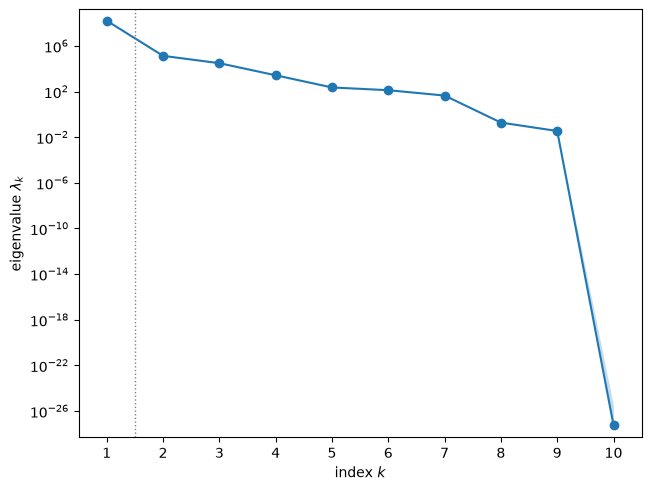

In [6]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
print(f'smallest eigenvalue lambda_10 = {lam[9]:.1e}; lambda_9 = {lam[8]:.1e}')
fig

$\lambda_1 = 1.596\times10^8$ (95 % bootstrap range $1.593$–$1.600\times10^8$) is 1188 times $\lambda_2 = 1.343\times10^5$ and holds 99.895 % of the trace; $\lambda_2/\lambda_3 = 4.40$, and the gap rule picks $n = 1$ (the eigenvalues are in (N/m)², so their size follows the load's). $\lambda_{10} = 5.9\times10^{-28}$ is a rounding error on the exactly null direction (equal steps in $f_1$ and $f_2$; the eigenvector cell checks it).

bootstrap mean subspace distance, k = 1..9: [3.937e-04 5.441e-03 4.431e-03 5.497e-03 2.241e-02 1.337e-02 1.130e-03
 5.666e-03 5.441e-15]


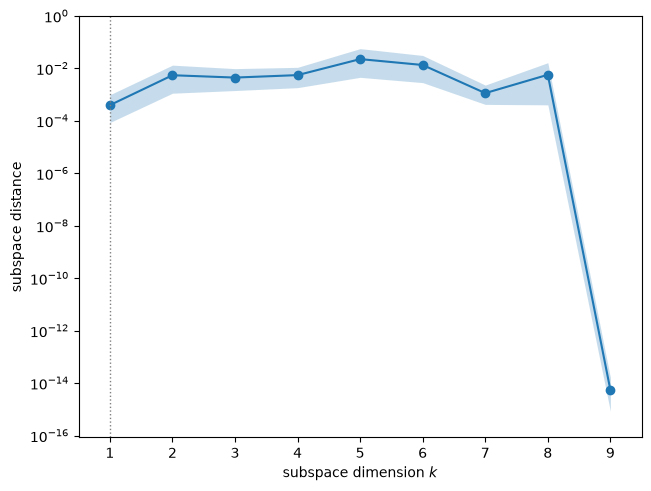

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..9:',
      np.array2string(sub.bootstrap_distances.mean(axis=0), precision=3))
fig

The bootstrap mean subspace distance for $n = 1$ is $3.9\times10^{-4}$: with 5000 exact gradients and a gap of three orders of magnitude, $\mathbf w_1$ is well determined. The distances for $k = 2$ to 8 are larger ($1.1\times10^{-3}$ to $2.2\times10^{-2}$) because the small trailing eigenvalues are closer together; for $k = 9$ it is $5.4\times10^{-15}$, since that subspace is the complement of the exact null direction.

w1: E +0.8849, nu +0.0582, h_c +0.0094, ell -0.2849, f_1 -0.1597, f_2 +0.0190, t +0.2629, a -0.0007, b_0 -0.1770, p +0.0773
w2: E +0.4313, nu -0.0608, h_c -0.0177, ell +0.7932, f_1 +0.2245, f_2 -0.0267, t -0.2723, a +0.0008, b_0 +0.1847, p -0.1465
|w10 . (f_1 + f_2 null direction)| = 1.000000
L w1 / sd (step along w1 in units of each sd): E +0.885, nu +0.058, h_c +0.009, ell -0.285, f_1 -0.160, f_2 +0.139, t +0.263, a -0.001, b_0 -0.177, p +0.077


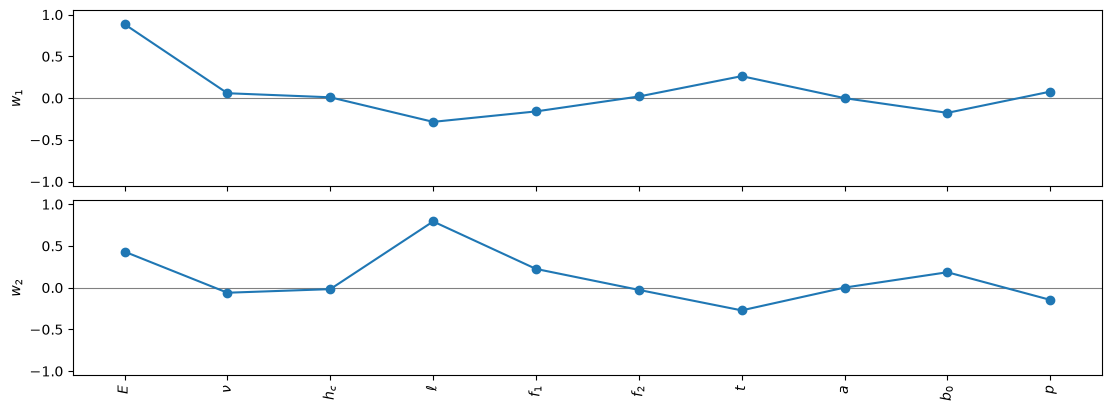

In [8]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(11, 4))
plt.close(fig)
w1, w2 = W[:, 0], W[:, 1]
print('w1:', ', '.join(f'{n} {v:+.4f}' for n, v in zip(names, w1)))
print('w2:', ', '.join(f'{n} {v:+.4f}' for n, v in zip(names, w2)))
# The QoI depends on f_1 and f_2 only through f_1 - f_2: equal physical steps in f_1 and f_2 change nothing.
L = np.linalg.cholesky(cov)
null = np.linalg.solve(L, np.r_[np.zeros(4), 1.0, 1.0, np.zeros(4)])   # that step in normalized coordinates
null /= np.linalg.norm(null)
print(f'|w10 . (f_1 + f_2 null direction)| = {abs(W[:, 9] @ null):.6f}')
# w1 as a relative change of each input: the step dx = L w1, divided by each input's sd
d1 = (L @ w1) / sd
print('L w1 / sd (step along w1 in units of each sd):', ', '.join(f'{n} {v:+.3f}' for n, v in zip(names, d1)))
fig

$\mathbf w_1$ weights $E$ by $+0.885$, $\ell$ by $-0.285$, $t$ by $+0.263$, $b_0$ by $-0.177$, $u_{f_1}$ by $-0.160$, $p$ by $+0.077$ and $\nu$ by $+0.058$; $u_{f_2}$ ($+0.019$), $h_c$ ($+0.009$) and $a$ ($-0.0007$) hardly matter. The signs are physical: the load grows with the stiffness $E t^3/(12(1-\nu^2))$ and with the stiffener half-width $p$, and falls with a wider strip $b_0$ (as $1/b_0^2$), a longer flank $\ell$ and a wider foot $f_1$ (both reduce the hat correction $Q$). The weight of $u_{f_2}$ is small because $f_2$ is strongly tied to $f_1$: written as a step in the original inputs, each in units of its standard deviation ($\mathbf L\mathbf w_1/\boldsymbol\sigma$, last printed line), $\mathbf w_1$ moves $f_1$ by $-0.160$ and $f_2$ by $+0.139$, i.e. along $f_1 - f_2$, the only combination the model sees. $\mathbf w_{10}$ is that null direction (inner product 1.000000). $\mathbf w_2$ is mostly $\ell$ ($+0.793$) and $E$ ($+0.431$); it carries the curvature of $Q$ in $\ell$ and of $E t^3$.

active variable y1 = w1^T u: range [-2.84, 2.70]; corr((N_xy)_cr, y1) = 0.999507


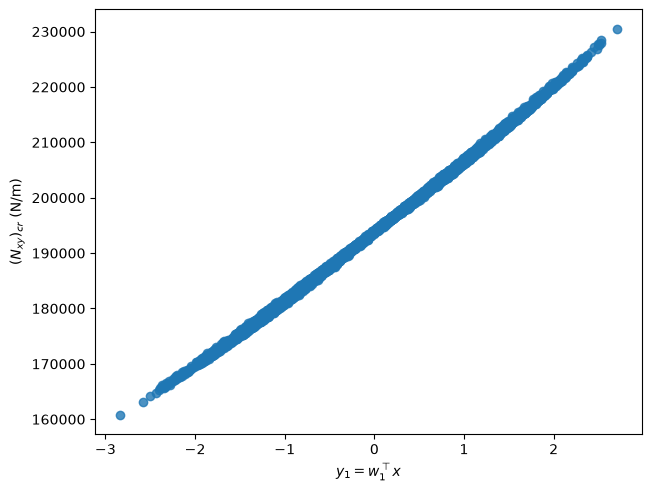

In [9]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label=r'$(N_{xy})_{cr}$ (N/m)')
plt.close(fig)
y = space.to_normalized(X) @ W[:, :2]
print(f'active variable y1 = w1^T u: range [{y[:, 0].min():.2f}, {y[:, 0].max():.2f}]; '
      f'corr((N_xy)_cr, y1) = {np.corrcoef(f, y[:, 0])[0, 1]:.6f}')
fig

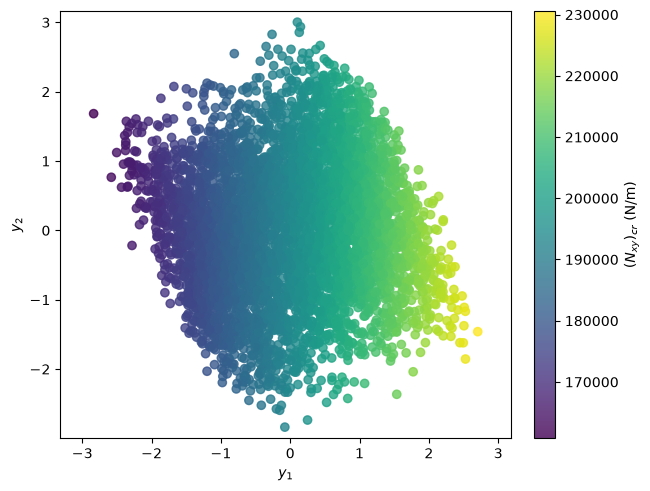

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=2, qoi_label=r'$(N_{xy})_{cr}$ (N/m)')
plt.close(fig)
fig

Against $y_1 = \mathbf w_1^T\mathbf u$ (range $-2.84$ to $2.70$), the load lies on a thin, almost straight band, with correlation 0.999507. In the $(y_1, y_2)$ plot the colour changes almost only along $y_1$.

#### Surrogates on the active variable

We fit polynomials in the active variables and report the leave-one-out $R^2$: a line and a quadratic in $y_1$, and a quadratic in $(y_1, y_2)$. The figure shows the quadratic in $y_1$.

LOO R^2: line in y1 0.999013; quadratic in y1 0.999564; quadratic in (y1, y2) 0.999865


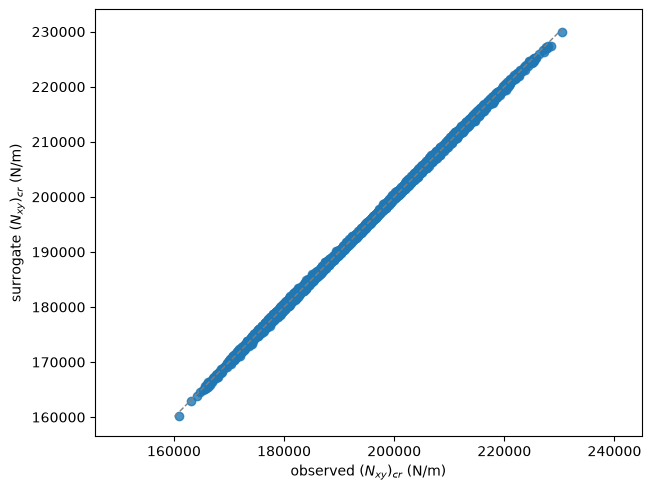

In [11]:
sur1 = ac.fit_surrogate(X=X, f=f, subspace=sub, kind='poly', degree=1)
sur2 = ac.fit_surrogate(X=X, f=f, subspace=sub, kind='poly', degree=2)
sur22 = ac.fit_surrogate(X=X, f=f, subspace=ac.with_dimension(sub, 2), kind='poly', degree=2)
print(f'LOO R^2: line in y1 {sur1.loo_r_squared:.6f}; quadratic in y1 {sur2.loo_r_squared:.6f}; '
      f'quadratic in (y1, y2) {sur22.loo_r_squared:.6f}')
fig, ax = ac.plotting.plot_surrogate_fit(sur2, X=X, f=f, qoi_label=r'$(N_{xy})_{cr}$ (N/m)')
plt.close(fig)
fig

A line in $y_1$ has leave-one-out $R^2 = 0.999013$, a quadratic 0.999564, and a quadratic in $(y_1, y_2)$ 0.999865. With input spreads of a few per cent, the load is close to linear in the inputs, and the one-dimensional subspace captures almost all of its variation.

#### The same analysis in Nataf variables

The affine normalization above keeps the inputs' distributions. The alternative for dependent inputs is the Nataf transform: each input through its own CDF to a standard normal, $z_j = \Phi^{-1}(F_j(x_j))$, which for a normal copula gives $\mathbf z \sim \mathcal N(\mathbf 0, \mathbf R)$ exactly, with $\mathbf R$ the copula's correlation matrix. One `ac.Gaussian(0, R)` block then whitens $\mathbf z$ with the Cholesky factor of $\mathbf R$, so the normalized variables are independent standard normals and the input space is exact. Each input again gets a unit-variance scale. The gradient is $\partial f/\partial z_j = \partial f/\partial x_j \cdot \varphi(z_j)/\rho_j(x_j)$ (`panel_model.dx_dz`). The cell also repeats the estimate for the linearization of the model at the mean, to show how much of the result comes from the transform itself.

eigenvalues: [1.669e+08 4.803e+06 1.758e+06 9.066e+05 5.973e+05 1.682e+05 9.194e+04
 4.077e+03 2.476e+03 1.364e+01]
n = 1; lambda_1/lambda_2 = 34.8, lambda_2/lambda_3 = 2.73
w1 (Nataf): E +0.9030, nu +0.0532, h_c +0.0086, ell -0.2617, f_1 -0.1471, f_2 +0.0168, t +0.2438, a -0.0007, b_0 -0.1638, p +0.0709
|w1(Nataf) . w1(affine)| = 0.9992
linearized model in the Nataf variables: lambda_1/lambda_2 = 35.6, lambda_2/lambda_3 = 2.70
LOO R^2, cubic in the Nataf y1: 0.97292


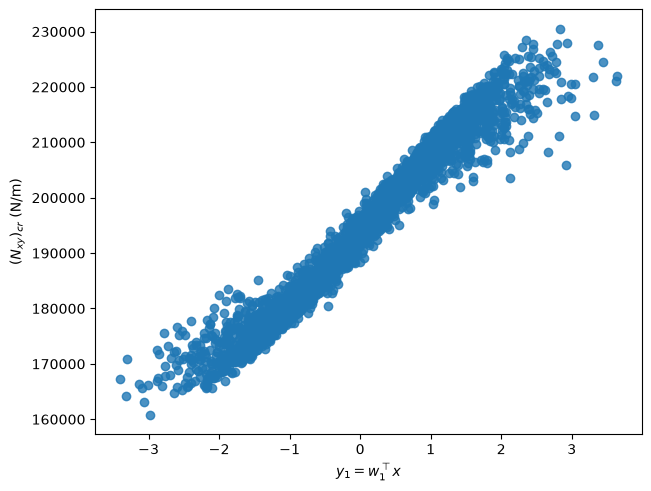

In [12]:
Z = pm.to_normal(X)                       # z_j = Phi^{-1}(F_j(x_j)) ~ N(0, R): the one conversion of the inputs
Gz = G * pm.dx_dz(X)                      # d(N_xy)_cr/dz_j = d(N_xy)_cr/dx_j * dx_j/dz_j
R = pm.copula_correlation()
space_z = ac.Gaussian(np.zeros(10), R, names=[f'z_{n}' for n in names])   # whitens z with the Cholesky factor of R
sub_z = ac.active_subspace(space=space_z, X=Z, f=f, grads=Gz, estimator='as', nboot=500, rng=SEED)
sub_z = ac.orient(sub_z, by='mean_gradient', grads=Gz)
lz, wz = sub_z.eigenvalues, sub_z.eigenvectors[:, 0]
print('eigenvalues:', np.array2string(lz, precision=3))
print(f'n = {sub_z.n}; lambda_1/lambda_2 = {lz[0] / lz[1]:.1f}, lambda_2/lambda_3 = {lz[1] / lz[2]:.2f}')
print('w1 (Nataf):', ', '.join(f'{n} {v:+.4f}' for n, v in zip(names, wz)))
print(f'|w1(Nataf) . w1(affine)| = {abs(wz @ w1):.4f}')
# The same estimate for the linearization of the model at the mean, f_lin(x) = f(mean) + grad f(mean) . (x - mean)
g0 = pm.grad_buckling_load(mean)
Gl = space_z.grads_to_normalized(g0 * pm.dx_dz(X))
ll = np.linalg.eigvalsh(Gl.T @ Gl / len(Gl))[::-1]
print(f'linearized model in the Nataf variables: lambda_1/lambda_2 = {ll[0] / ll[1]:.1f}, '
      f'lambda_2/lambda_3 = {ll[1] / ll[2]:.2f}')
sur_z = ac.fit_surrogate(X=Z, f=f, subspace=sub_z, kind='poly', degree=3)
print(f'LOO R^2, cubic in the Nataf y1: {sur_z.loo_r_squared:.5f}')
fig, ax = ac.plotting.plot_sufficient_summary(sub_z, X=Z, f=f, dims=1, qoi_label=r'$(N_{xy})_{cr}$ (N/m)')
plt.close(fig)
fig

The direction hardly changes, $|\mathbf w_1^{\mathrm{Nataf}}\cdot\mathbf w_1| = 0.9992$, with the same order of weights ($E$ $+0.903$, $\ell$ $-0.262$, $t$ $+0.244$, $b_0$ $-0.164$, $f_1$ $-0.147$). The eigenvalue ratio does change: $\lambda_1/\lambda_2 = 34.8$ ($\lambda_2/\lambda_3 = 2.73$) instead of 1188, and a cubic in the Nataf $y_1$ has leave-one-out $R^2 = 0.97292$ instead of 0.99956 for a quadratic in the affine $y_1$. The linearized model gives nearly the same ratio in the Nataf variables (35.6), so the drop comes from the transform, not from the model: for a uniform input, $x = a + (b-a)\Phi(z)$ is S-shaped in $z$, and a function that is linear in $x$ becomes curved in $z$, which spreads the gradient over more directions. For this nearly linear model the affine normalization is the more faithful description, and we use it as the main result.

#### Two more checks

(a) The same affine scaling without the decorrelation of $f_1$ and $f_2$ (a diagonal covariance). (b) **The OpenTURNS-as-coded thickness**, $t$ uniform on $[8.02, 8.181]\times10^{-5}$ m: the cell redraws the samples with the same seed and generator (`panel_model.sample(..., variant='openturns')`), so every other input is identical to `inputs.csv` and $t$ is exactly ten times smaller, and repeats the main estimate with that variant's own exact mean and covariance.

In [13]:
def as_ratio(space_, X_, G_):
    Gn = space_.grads_to_normalized(G_)
    l_, W_ = np.linalg.eigh(Gn.T @ Gn / len(Gn))
    l_, W_ = l_[::-1], W_[:, ::-1]
    return l_[0] / l_[1], W_[:, 0] * np.sign(W_[0, 0])

# (a) correlation ignored in the normalization: every input scaled by its sd, f_1 and f_2 not decorrelated
r_d, w_d = as_ratio(ac.Gaussian(mean, np.diag(cov), names=names), X, G)
print(f'(a) diagonal scaling: lambda_1/lambda_2 = {r_d:.0f}; |w1 . w1(main)| = {abs(w_d @ w1):.6f}')
# (b) the OpenTURNS-as-coded thickness, t in [8.02e-5, 8.181e-5] m: the same draws, so only the t column changes
X_ot = pm.sample(len(X), np.random.default_rng(SEED), variant='openturns')
mean_ot, cov_ot = pm.mean_and_cov(variant='openturns')
f_ot, G_ot = pm.buckling_load(X_ot), pm.grad_buckling_load(X_ot)
other = np.r_[0:6, 7:10]
print(f'(b) OpenTURNS thickness: other columns identical to inputs.csv: {np.array_equal(X_ot[:, other], X[:, other])}; '
      f't / t_OpenTURNS in [{(X[:, 6] / X_ot[:, 6]).min():.6f}, {(X[:, 6] / X_ot[:, 6]).max():.6f}]')
r_ot, w_ot = as_ratio(ac.Gaussian(mean_ot, cov_ot, names=names), X_ot, G_ot)
print(f'    (N_xy)_cr mean {f_ot.mean():.3f} N/m (main data / variant = {f.mean() / f_ot.mean():.1f}); '
      f'lambda_1/lambda_2 = {r_ot:.0f}; |w1 . w1(main)| = {abs(w_ot @ w1):.6f}')
q_ot = pm.intermediates(pm.NOMINAL_OPENTURNS)
print(f'    at the midpoint with t = {pm.NOMINAL_OPENTURNS[6]:.6g} m ({pm.NOMINAL_OPENTURNS[6] / 0.0254:.5f} in): '
      f'(N_xy)_cr = {pm.buckling_load(pm.NOMINAL_OPENTURNS):.3f} N/m = '
      f'{pm.buckling_load(pm.NOMINAL_OPENTURNS) / LBF_PER_IN:.4f} lb/in (Q = {q_ot["Q"]:.4f})')

(a) diagonal scaling: lambda_1/lambda_2 = 1196; |w1 . w1(main)| = 0.999603
(b) OpenTURNS thickness: other columns identical to inputs.csv: True; t / t_OpenTURNS in [10.000000, 10.000000]
    (N_xy)_cr mean 198.111 N/m (main data / variant = 980.2); lambda_1/lambda_2 = 1153; |w1 . w1(main)| = 0.999904
    at the midpoint with t = 8.1005e-05 m (0.00319 in): (N_xy)_cr = 197.762 N/m = 1.1292 lb/in (Q = 1.3323)


Ignoring the correlation in the normalization changes almost nothing ($\lambda_1/\lambda_2 = 1196$, $|\mathbf w_1\cdot\mathbf w_1| = 0.999603$): $f_1$ and $f_2$ carry little of the variation. With the OpenTURNS-as-coded thickness the load is 980.2 times smaller on average (mean 198.111 N/m: the $t^3$ factor, partly offset by the hat correction, which is 1.3323 instead of 1.3060 at the midpoint, where the load is 197.762 N/m = 1.1292 lb/in), but the active subspace is practically the same ($\lambda_1/\lambda_2 = 1153$, $|\mathbf w_1\cdot\mathbf w_1| = 0.999904$), because the relative spread of $t$ is the same. The choice of thickness changes the level of the load, not the structure found here.

### Comparison with the paper

Neither source reports an active subspace or a sensitivity analysis. The OpenTURNS page gives the model and the distributions but no numbers computed from them. The memorandum (as far as we could read it) gives a local shear buckling load of 900 lb/in from a finite-element analysis, says that its closed-form (flat-plate) local prediction is slightly higher than that value, and gives a global shear buckling load of 4296 lb/in (its Eq. 43); we compare the first with the formula, for both thicknesses. The cell also ranks the inputs by their activity scores $\alpha_j = \lambda_1 w_{1j}^2$ [[5]][R5].

In [14]:
from scipy.optimize import brentq
alpha = lam[0] * w1**2                     # activity scores of the one-dimensional subspace
order = np.argsort(-alpha)
print('inputs by activity score alpha_j = lambda_1 w1j^2 (share of the trace):')
print('  ' + ', '.join(f'{names[i]} {alpha[i] / lam.sum():.4f}' for i in order))
print(f'k_xy at the midpoint {pm.intermediates(pm.NOMINAL)["kxy"]:.4f}; '
      f'over the samples [{q["kxy"].min():.4f}, {q["kxy"].max():.4f}]')
N0 = pm.buckling_load(pm.NOMINAL) / LBF_PER_IN
q0 = pm.intermediates(pm.NOMINAL)
print(f'(N_xy)_cr at the midpoint: {N0 * LBF_PER_IN:.0f} N/m = {N0:.0f} lb/in (flat strip alone, Q = 1: '
      f"{q0['strip'] / LBF_PER_IN:.0f} lb/in); TM finite-element local load 900 lb/in = {900 * LBF_PER_IN:.0f} N/m")
print(f'formula / TM finite-element load at the midpoint = {N0 / 900:.3f} (flat strip alone {q0["strip"] / LBF_PER_IN / 900:.3f}); '
      f'sample mean / 900 lb/in = {f.mean() / LBF_PER_IN / 900:.3f}')
def load_at_t(tt):
    x = pm.NOMINAL.copy()
    x[6] = tt
    return pm.buckling_load(x) / LBF_PER_IN
t900 = brentq(lambda tt: load_at_t(tt) - 900, 1e-5, 1e-2)
print(f'thickness giving exactly 900 lb/in at the midpoint of the other inputs: {t900:.4e} m = {t900 / 0.0254:.4f} in')
print(f'OpenTURNS-as-coded thickness: 900 lb/in / midpoint load = {900 / (pm.buckling_load(pm.NOMINAL_OPENTURNS) / LBF_PER_IN):.0f}; '
      f'TM global / local (finite-element) load = 4296 / 900 = {4296 / 900:.2f}')

inputs by activity score alpha_j = lambda_1 w1j^2 (share of the trace):
  E 0.7822, ell 0.0811, t 0.0691, b_0 0.0313, f_1 0.0255, p 0.0060, nu 0.0034, f_2 0.0004, h_c 0.0001, a 0.0000
k_xy at the midpoint 5.3718; over the samples [5.3709, 5.3726]
(N_xy)_cr at the midpoint: 193859 N/m = 1107 lb/in (flat strip alone, Q = 1: 848 lb/in); TM finite-element local load 900 lb/in = 157614 N/m
formula / TM finite-element load at the midpoint = 1.230 (flat strip alone 0.942); sample mean / 900 lb/in = 1.232
thickness giving exactly 900 lb/in at the midpoint of the other inputs: 7.5569e-04 m = 0.0298 in
OpenTURNS-as-coded thickness: 900 lb/in / midpoint load = 797; TM global / local (finite-element) load = 4296 / 900 = 4.77


| Quantity | Paper value | Notebook value |
|---|---|---|
| $k_{xy}$ | $5.35 + 4(b/a)^2$; 5.35 (infinitely long strip), 9.34 (square plate) [1] | 5.3718 at the midpoint; 5.3709–5.3726 over the samples |
| Local $(N_{xy})_{cr}$ | 900 lb/in (157614 N/m), finite elements; closed-form prediction "slightly higher" [1] | 1107 lb/in (193859 N/m) at the midpoint, 1.230 times 900 lb/in; flat strip alone ($Q = 1$) 848 lb/in, 0.942 times; sample mean 194195 N/m (95 % interval 193840–194550), 1.232 times; range 918–1316 lb/in |
| Local $(N_{xy})_{cr}$, OpenTURNS-as-coded $t$ | not reported (OpenTURNS gives no values) | 1.1292 lb/in (197.762 N/m) at the midpoint, 797 times below 900 lb/in |
| Thickness $t$ | not legible in the text we could read | used: 0.0316–0.0322 in; 0.0298 in ($7.5569\times10^{-4}$ m) would give exactly 900 lb/in at the midpoint of the other inputs |
| Global $(N_{xy})_{cr}$ | 4296 lb/in [1, Eq. 43] | not modelled |
| Active subspace | not reported | $n = 1$, $\lambda_1/\lambda_2 = 1188$ (affine, decorrelated), 34.8 (Nataf), 1153 with the OpenTURNS $t$; line in $y_1$: LOO $R^2 = 0.999013$ |
| Most important inputs | not reported | by $\alpha_j$: $E$ (0.7822 of the trace), $\ell$ (0.0811), $t$ (0.0691), $b_0$ (0.0313), $f_1$ (0.0255) |

**The thickness.** The OpenTURNS benchmark's thickness range appears to be a factor-10 slip, and the data here follow the memorandum's panel. The evidence: (1) with the thickness as coded in OpenTURNS, $8.02$–$8.181\times10^{-5}$ m (0.0032 in, a 0.08 mm foil), the formula gives 1.13 lb/in at the midpoint, 797 times below the memorandum's finite-element value of 900 lb/in; (2) with ten times that thickness, the range used here (0.032 in, a standard gauge of titanium sheet, consistent with $E = 110$ GPa), it gives 1107 lb/in, 1.23 times the finite-element value, in line with the memorandum's statement that its closed-form prediction is slightly higher than the finite-element one (the flat strip alone gives 848 lb/in, 0.94 times); (3) a thickness of 0.0298 in would give exactly 900 lb/in. We could not read the memorandum's dimensions, so we cannot say which closed form (with or without the hat correction $Q$) and which exact thickness it used, nor how much higher "slightly higher" is; the evidence settles the factor of ten, not the last 20 %. The OpenTURNS-as-coded thickness gives the same active subspace (check (b)); only the level of the load differs.

**What the memorandum compares.** Its abstract says that the flat-plate prediction of the local buckling load compares favourably with the finite-element result and that the global buckling load is several times higher than the local one; 4296/900 = 4.77 is consistent with that.

### References

[1] W. L. Ko and R. H. Jackson. [Shear Buckling Analysis of a Hat-Stiffened Panel](https://ntrs.nasa.gov/citations/19950011075). NASA Technical Memorandum 4644, NASA Dryden Flight Research Center, Edwards, California, November 1994. No DOI; NTRS 19950011075.

[2] OpenTURNS 1.25 documentation, use case [The stiffened panel model](https://openturns.github.io/openturns/1.25/usecases/use_case_stiffened_panel.html) (accessed 2026-10-30), and its code, `python/src/usecases/stiffened_panel.py` at tag [v1.25.1](https://github.com/openturns/openturns/blob/v1.25.1/python/src/usecases/stiffened_panel.py) (read 2026-10-31; identical to master on that date). Source of the formula and the input distributions used here (with the thickness range scaled by 10).

[3] M. Baudin, A. Dutfoy, B. Iooss, and A.-L. Popelin. [OpenTURNS: An Industrial Software for Uncertainty Quantification in Simulation](https://doi.org/10.1007/978-3-319-12385-1_64). In *Handbook of Uncertainty Quantification*, Springer, Cham, 2017, pp. 2001–2038.

[4] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, Philadelphia, 2015.

[5] P. G. Constantine and P. Diaz. [Global sensitivity metrics from active subspaces](https://doi.org/10.1016/j.ress.2017.01.013). *Reliability Engineering & System Safety*, 162:1–13, 2017.

[R1]: https://ntrs.nasa.gov/citations/19950011075
[R2]: https://openturns.github.io/openturns/1.25/usecases/use_case_stiffened_panel.html
[R4]: https://doi.org/10.1137/1.9781611973860
[R5]: https://doi.org/10.1016/j.ress.2017.01.013

In [15]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 3.2 s
